# 4. Isochrones in the HR diagram

In the previous tutorial, we followed the luminosity and luminosity-weighted mean effective temperature of a stellar population through time. To understand how individual stars contribute to these changing population properties, we can examine their positions in the **Hertzsprung–Russell (HR) diagram**, which plots luminosity against effective temperature.

For stars with a common age and initial composition, the positions predicted by an evolutionary model trace an **isochrone**. Because evolutionary timescales depend on initial mass, stars formed together can occupy different evolutionary stages along this curve.

In this tutorial, we will construct isochrones with ARSENAL, plot them in the HR diagram, and compare several ages to see how the isochrones change as the population evolves.

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
import arsenal_gear as ag

As always, we start by recreating the SSP from the previous tutorials.

In [38]:
ssp_parameters = {
    "type": "single",
    "Mtot": 1e5 * u.Msun,
    "tform": 0 * u.Myr,
    "metallicity": 0.0,
    "rotation": 0.0,
    "imf": "kroupa2001",
    "mmin": 0.1 * u.Msun,
    "mmax": 100 * u.Msun,
    "discrete": True,
    "seed": 42,
}

sp = ag.SynthPop(pop1=ssp_parameters, interp_op="iso", vvcrit="0.0")
pop = sp.form.subpops[0]
se = sp.evol.ses[0]

## Construct an isochrone

We use the population’s evolutionary interpolator, `se`, to construct an isochrone at a chosen stellar age. The method `se.construct_isochrone(age)` returns an `Isochrone` object containing the stellar properties at a finite set of model points along the curve. These points span an age-dependent range of initial masses determined by the evolutionary models.

We first request an isochrone at an age of $1\,\mathrm{Gyr}$. Unlike the population methods `sp.lbol(t)` and `sp.teff(t)`, `se.construct_isochrone(age)` takes stellar age directly:

$$
\tau=t-t_{\mathrm{form}}.
$$

In [39]:
age = 1 * u.Gyr
iso = se.construct_isochrone(age)

print(type(se).__name__)
print(type(iso).__name__)
print(f"Initial masses represented at {age}: {iso.m0.min():.3f} to {iso.m0.max():.3f}")
print(f"Number of model points: {len(iso.m0)}")

IsochroneInterpolator
Isochrone
Initial masses represented at 1.0 Gyr: 0.106 solMass to 2.307 solMass
Number of model points: 1516


We can access the stellar properties stored in `iso` through the following attributes:

| Attribute | Contents |
|---|---|
| `iso.m0` | Initial stellar masses, in solar masses |
| `iso.teff` | Effective temperatures, in kelvin |
| `iso.lbol` | Bolometric luminosities, in solar luminosities |
| `iso.qs` | Dictionary containing the model quantities along the isochrone, stored as numerical arrays |

For each initial mass in `iso.m0`, the corresponding entries in `iso.teff` and `iso.lbol` give the predicted temperature and luminosity.

For a given set of evolutionary models, populations with the same age, initial chemical composition and rotation share an isochrone, even if their stellar mass distributions differ. Their sampled masses determine how many stars occupy each part of the isochrone and how much those stars contribute to the population’s light.

## Plot the isochrone in the HR diagram

We plot luminosity vertically and effective temperature horizontally. By convention, temperature decreases towards the right: hot stars lie on the left, and luminous stars lie towards the top.

A cool star can still be very luminous if it has a large radius, since

$$
L=4\pi R^2\sigma_{\mathrm{SB}}T_{\mathrm{eff}}^4.
$$

This explains why giants can appear above main-sequence stars of similar temperature, while compact white dwarfs can be hot but faint.

Luminosity can also be expressed as an absolute bolometric magnitude; that is, the magnitude the star would have if it were placed at a standard distance of $10\,\mathrm{pc}$, including radiation at all wavelengths:

$$
M_{\mathrm{bol}}=M_{{bol},\odot}-2.5\log_{10}(L/L_\odot), \qquad M_{\mathrm{bol},\odot}=4.74.
$$

The right-hand axis will show this scale: smaller, more negative magnitudes correspond to greater luminosity.

The top axis shows the spectral sequence O, B, A, F, G, K, M, from hotter to cooler stars. Because these classes are defined by spectral features rather than temperature alone, we place the labels at representative temperatures as an approximate guide. Wolf–Rayet stars and white dwarfs fall outside this sequence and have their own spectral classifications.

We define the axis formatting once so that all the diagrams use the same conventions:

In [40]:
def format_hr_diagram(ax, extra_axes=True):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.xaxis.set_inverted(True)
    ax.set_xlabel(r"Effective temperature $T_{\mathrm{eff}}$ [K]")
    ax.set_ylabel(r"Bolometric luminosity $L/L_\odot$")
    ax.grid(alpha=0.2)

    if extra_axes:
        mag_ax = ax.twinx()
        mag_ax.set_ylim(4.74 - 2.5 * np.log10(ax.get_ylim()))
        mag_ax.set_ylabel(r"Absolute bolometric magnitude $M_{\mathrm{bol}}$")

        spectral_ax = ax.twiny()
        spectral_ax.set_xscale("log")
        spectral_ax.set_xticks([40000, 15000, 8500, 6750, 5600, 4400, 3200],
                              labels=["O", "B", "A", "F", "G", "K", "M"])
        spectral_ax.set_xlim(ax.get_xlim())
        spectral_ax.minorticks_off()
        spectral_ax.set_xlabel("Approximate spectral class")

We colour the model points by initial mass. The connecting line follows their order in the isochrone table, tracing the curve at our chosen age.

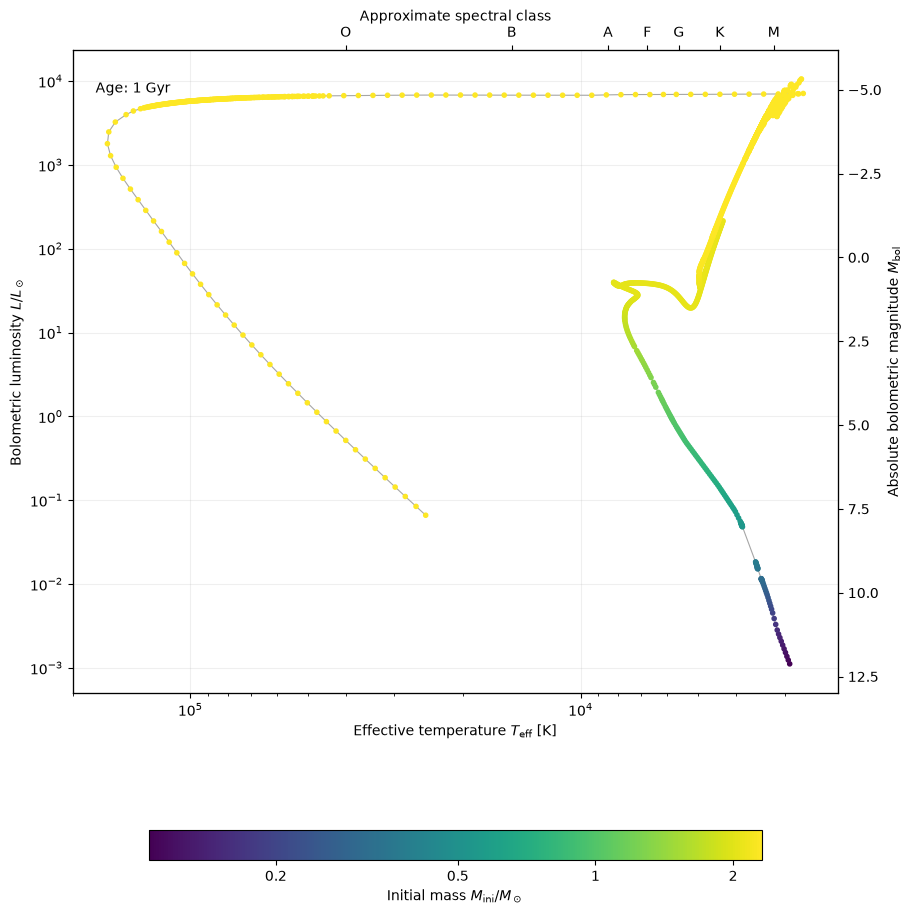

In [41]:
teff = iso.teff.to_value(u.K)
lbol = iso.lbol.to_value(u.Lsun)
initial_mass = iso.m0.to_value(u.Msun)

fig, ax = plt.subplots(figsize=(9, 9), layout="constrained")
ax.plot(teff, lbol, color="0.65", linewidth=0.8, zorder=1)
points = ax.scatter(teff, lbol, c=initial_mass, norm=LogNorm(), cmap="viridis", s=9, zorder=2)
ax.text(0.03, 0.95, "Age: 1 Gyr", transform=ax.transAxes, va="top")
format_hr_diagram(ax)

colourbar = fig.colorbar(points, ax=ax, orientation="horizontal", pad=0.12, shrink=0.8)
colourbar.set_label(r"Initial mass $M_{\mathrm{ini}}/M_\odot$")
colourbar.set_ticks([0.2, 0.5, 1, 2], labels=["0.2", "0.5", "1", "2"])
colourbar.minorticks_off()
plt.show()

The **main sequence** rises diagonally upwards and to the left from the cool, faint lower-right region. Its stars fuse hydrogen in their cores, with higher initial masses generally corresponding to higher temperatures and luminosities. At the **main-sequence turnoff**, stars approach core hydrogen exhaustion and begin to leave this stage.

Their subsequent evolution depends on initial mass and composition. In this isochrone, the cool side contains the **red giant branch**, the **red-clump region** associated with core helium burning, and the **asymptotic giant branch (AGB)**. Towards the end of the AGB, stars lose most of their outer envelopes through stellar winds. They then pass through the hot **post-AGB** phase before joining the declining **white dwarf cooling sequence**. More massive stars, represented at younger ages, can instead occupy luminous blue and red **supergiant** regions.

The gap between points on the lower main sequence reflects how the models are sampled. MIST uses **equivalent evolutionary points (EEPs)** to identify corresponding evolutionary stages across stellar models, so the resulting isochrone points are not evenly spaced in initial mass. ARSENAL interpolates between these points when evaluating stars with intermediate masses.

## Compare isochrones at different ages

Higher-mass stars use their nuclear fuel more rapidly, so they leave the main sequence first. As a population ages, its turnoff moves towards lower initial masses and, in general, lower luminosities and temperatures.

We compare the same population at ages of $1\,\mathrm{Myr}$, $10\,\mathrm{Myr}$, $1\,\mathrm{Gyr}$, and $10\,\mathrm{Gyr}$, all four within the MIST grid used here. We use a shared colour scale so that the same colour represents the same initial mass in every panel.

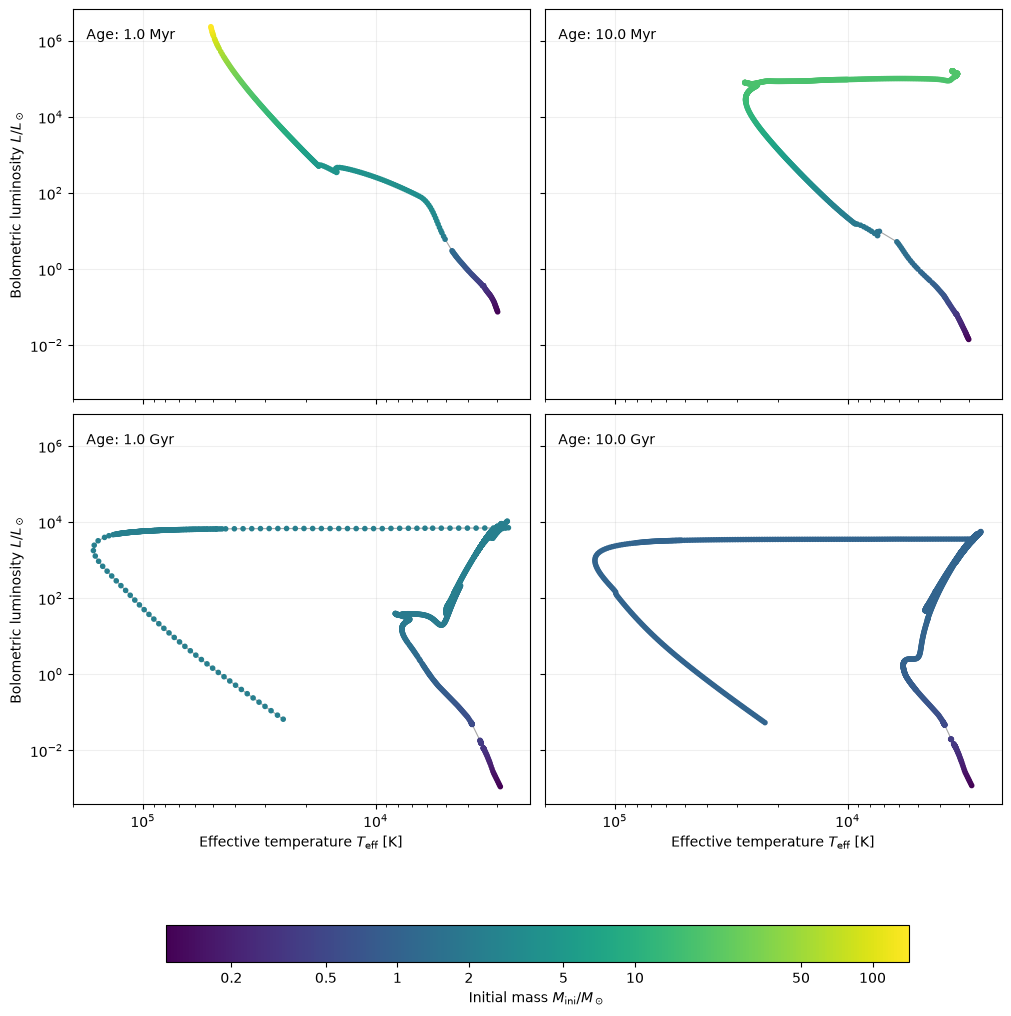

In [42]:
ages = [1 * u.Myr, 10 * u.Myr, 1 * u.Gyr, 10 * u.Gyr]
isochrones = [se.construct_isochrone(age) for age in ages]
mass_arrays = [age_iso.m0.to_value(u.Msun) for age_iso in isochrones]
norm = LogNorm(vmin=min(m.min() for m in mass_arrays), vmax=max(m.max() for m in mass_arrays))

fig, axes = plt.subplots(2, 2, figsize=(10,10), sharex=True, sharey=True, layout="constrained")

for ax, age, age_iso, initial_mass in zip(axes.flat, ages, isochrones, mass_arrays):
    teff = age_iso.teff.to_value(u.K)
    lbol = age_iso.lbol.to_value(u.Lsun)

    ax.plot(teff, lbol, color="0.65", linewidth=0.8, zorder=1)
    points = ax.scatter(teff, lbol, c=initial_mass, norm=norm, cmap="viridis", s=9, zorder=2)
    ax.text(0.03, 0.95, f"Age: {age}", transform=ax.transAxes, va="top")
    format_hr_diagram(ax, extra_axes=False)
    ax.label_outer()

colourbar = fig.colorbar(points, ax=axes, orientation="horizontal", pad=0.08, shrink=0.8)
colourbar.set_label(r"Initial mass $M_{\mathrm{ini}}/M_\odot$")
colourbar.set_ticks([0.2, 0.5, 1, 2, 5, 10, 50, 100], labels=["0.2", "0.5", "1", "2", "5", "10", "50", "100"])
colourbar.minorticks_off()
plt.show()

At **1 Myr**, massive stars occupy the hot, luminous upper main sequence. Lower-mass stars are still contracting towards the main sequence, producing the cooler sequence extending towards the lower right.

At **10 Myr**, the most massive stars represented in the youngest isochrone have completed their modelled evolution. The main sequence now shows a clear turnoff, followed by a nearly horizontal sequence of luminous evolved stars extending towards cool red supergiants in the upper-right part of the panel.

At **1 Gyr**, the turnoff corresponds to initial masses of roughly $2\,M_\odot$. The giant and AGB branches extend upwards on the cool side of the diagram. The nearly horizontal upper section represents hot post-AGB evolution, followed by a declining sequence towards faint white dwarfs.

By **10 Gyr**, these broad features remain, but the turnoff has shifted to lower temperatures and luminosities, corresponding to initial masses close to $1\,M_\odot$. The evolved branches also involve stars born with lower masses, as shown by their bluer colours on the shared initial-mass scale.